<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/08_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Model Comparison & Error Analysis

## 1. Comparaison des performances

### Objectif DSO3

Comparer les performances des architectures de Deep Learning utilisées pour détecter et segmenter les anomalies routières.

Les modèles étudiés sont :

- CNN Baseline
- U-Net
- FCN
- U-Net ResNet34
- Mask R-CNN

Les modèles de segmentation sémantique sont comparés avec IoU, Dice, Precision et Recall au niveau des pixels.

Mask R-CNN est évalué séparément avec des métriques de segmentation des instances (Mask IoU, Precision, Recall et AP@50), car elles ne sont pas directement comparables aux métriques par pixel.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Résultats sur les images de test
semantic_results = pd.DataFrame({
    "Model": [
        "CNN Baseline",
        "U-Net",
        "U-Net ResNet34"
    ],
    "IoU": [0.1925, 0.2707, 0.7351],
    "Dice": [0.3229, 0.4260, 0.8474],
    "Precision": [0.4104, 0.3582, 0.8152],
    "Recall": [0.2661, 0.5257, 0.8822]
})

semantic_results = semantic_results.sort_values(
    by="IoU", ascending=False
).reset_index(drop=True)

display(semantic_results)

,Model,IoU,Dice,Precision,Recall
0,U-Net ResNet34,0.7351,0.8474,0.8152,0.8822
1,U-Net,0.2707,0.4260,0.3582,0.5257
2,CNN Baseline,0.1925,0.3229,0.4104,0.2661


## 2. Comparaison graphique des modèles

Nous comparons les performances des modèles de segmentation sémantique sur les 9 images de test.

Les métriques étudiées sont :
- **IoU :** mesure le chevauchement entre les régions prédites et réelles.
- **Dice :** mesure la similarité des masques.
- **Precision :** mesure la proportion de pixels prédits comme anomalies qui sont réellement anormaux.
- **Recall :** mesure la proportion de pixels anormaux correctement détectés.

L'objectif est d'identifier le modèle offrant le meilleur équilibre entre détection et précision.

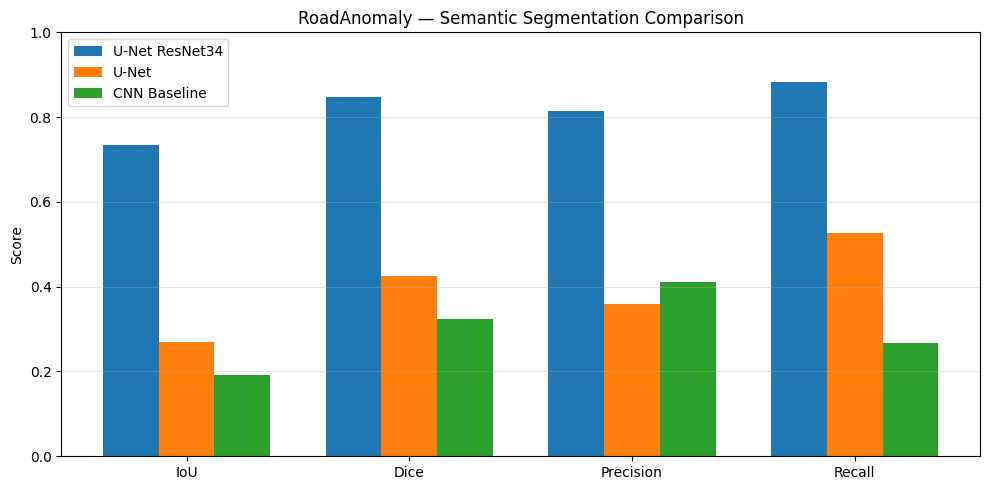

In [2]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["IoU", "Dice", "Precision", "Recall"]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

for i, row in semantic_results.iterrows():
    values = row[metrics].astype(float).to_numpy()

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=row["Model"]
    )

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("RoadAnomaly — Semantic Segmentation Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Évaluation de la segmentation des instances

Mask R-CNN est utilisé pour identifier et segmenter individuellement les obstacles routiers.

Le modèle a été évalué sur 8 images de test contenant 24 obstacles annotés.

Les métriques utilisées sont :
- **Mask IoU :** qualité moyenne des masques correctement associés.
- **Precision :** proportion des détections correctes.
- **Recall :** proportion des obstacles détectés.
- **AP@50 :** Average Precision avec un seuil de Mask IoU de 0.5.

Les résultats sont analysés séparément des modèles de segmentation sémantique.

,Metric,Score
0,Mask IoU,0.7378
1,Precision,0.3714
2,Recall,0.5417
3,AP@50,0.5402


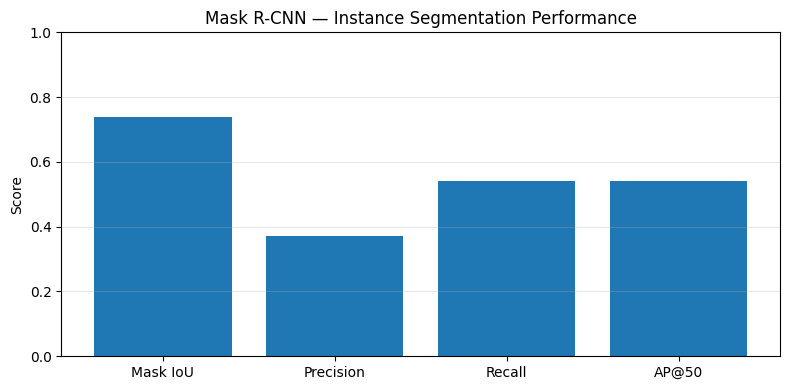

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

instance_results = pd.DataFrame({
    "Metric": [
        "Mask IoU",
        "Precision",
        "Recall",
        "AP@50"
    ],
    "Score": [
        0.7378,
        0.3714,
        0.5417,
        0.5402
    ]
})

display(instance_results)

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    instance_results["Metric"],
    instance_results["Score"]
)

ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Mask R-CNN — Instance Segmentation Performance")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Analyse des erreurs

### 4.1. Segmentation sémantique

**CNN Baseline**
- IoU faible (0.1925) et Recall limité (0.2661).
- De nombreux pixels anormaux ne sont pas détectés.
- Segmentation imprécise des obstacles.

**U-Net**
- Amélioration du Recall (0.5257) et du Dice (0.4260).
- Davantage de pixels anormaux sont détectés.
- Présence de faux positifs sur des éléments de la route et du décor.

**U-Net ResNet34**
- Meilleures performances globales : IoU de 0.7351 et Dice de 0.8474.
- Bonne détection des anomalies avec un Recall de 0.8822.
- Certaines limites persistent dans la délimitation des obstacles : masques trop larges ou fragmentés.

### 4.2. Segmentation des instances

**Mask R-CNN**
- 13 obstacles correctement détectés sur 24.
- 22 faux positifs et 11 faux négatifs.
- Precision limitée à 0.3714.
- Mask IoU de 0.7378 pour les instances correctement associées.

Les visualisations montrent que Mask R-CNN peut localiser individuellement des obstacles, mais produit aussi des détections incorrectes et peut manquer certains objets.

### 4.3. Limites du projet

- Dataset limité à 60 images, dont seulement 46 annotées pour les instances.
- Petit ensemble de test : 9 images pour la segmentation sémantique et 8 pour la segmentation des instances.
- Variabilité des obstacles, de leur taille et des conditions visuelles.
- Risque de surapprentissage, notamment observé pendant l'entraînement de Mask R-CNN.
- Difficulté à généraliser les performances à de nouvelles scènes routières.

### 4.4. Pistes d'amélioration

- Augmenter la diversité et la taille du dataset.
- Tester davantage d'augmentations de données.
- Optimiser les hyperparamètres sur la validation.
- Étudier différentes résolutions d'entrée.
- Utiliser un ensemble de test indépendant plus important.
- Réduire les faux positifs de Mask R-CNN et améliorer la délimitation des petits obstacles.

## 5. Conclusion générale du projet RoadAnomaly

### 5.1. Business Objective (BO)

L'objectif du projet RoadAnomaly est de contribuer à la sécurité routière grâce à la détection et à la localisation automatiques d'obstacles inhabituels sur la chaussée.

Nous avons étudié plusieurs architectures de Deep Learning capables d'identifier les anomalies dans des images routières.

### 5.2. Data Science Objective 1 — Segmentation sémantique

Nous avons développé plusieurs modèles de segmentation sémantique :

- CNN Baseline
- U-Net
- U-Net ResNet34

**U-Net ResNet34 obtient les meilleures performances :**

| Métrique | Résultat |
|---|---|
| IoU | 0.7351 |
| Dice | 0.8474 |
| Precision | 0.8152 |
| Recall | 0.8822 |

Ce modèle permet de détecter et de segmenter une grande partie des régions anormales sur les images de test.

### 5.3. Data Science Objective 2 — Segmentation des instances

Nous avons utilisé Mask R-CNN avec un backbone ResNet50-FPN pour identifier individuellement les obstacles.

**Résultats :**

- Mask IoU : 0.7378 sur les instances correctement associées.
- Precision : 0.3714.
- Recall : 0.5417.
- AP@50 : 0.5402.

Mask R-CNN a correctement détecté 13 obstacles sur 24, mais a également produit 22 faux positifs.

Il démontre la possibilité de distinguer plusieurs objets dans une même scène, mais ses performances restent limitées.

### 5.4. Data Science Objective 3 — Comparaison et analyse des erreurs

La comparaison des architectures montre que :

- CNN Baseline fournit un premier modèle de référence.
- U-Net améliore la détection des régions anormales.
- U-Net ResNet34 obtient les meilleurs résultats de segmentation sémantique.
- Mask R-CNN permet une analyse au niveau des obstacles individuels.

Les principales erreurs concernent les faux positifs, les obstacles non détectés et les imprécisions dans les contours des masques.

Les résultats de segmentation sémantique et de segmentation des instances sont analysés séparément en raison de leurs différences méthodologiques.

### 5.5. Limites et perspectives

Le dataset contient seulement 60 images, dont 46 disposent d'annotations d'instances.

Les résultats restent donc exploratoires et ne permettent pas de garantir une généralisation à des conditions routières réelles.

Les améliorations futures pourraient inclure :

- Un dataset plus volumineux et diversifié.
- Une validation sur de nouvelles scènes routières.
- L'optimisation des hyperparamètres.
- L'amélioration de la détection des petits obstacles.
- Une évaluation de la vitesse d'inférence pour envisager une application en temps réel.

### 5.6. Conclusion finale

Le projet RoadAnomaly démontre l'intérêt du Deep Learning pour la détection et la segmentation des anomalies routières.

U-Net ResNet34 constitue le meilleur modèle de segmentation sémantique parmi les architectures évaluées, tandis que Mask R-CNN apporte la capacité de détecter et segmenter les obstacles individuellement.

Les résultats sont encourageants, mais des données supplémentaires et une validation plus approfondie sont nécessaires avant toute application opérationnelle.